In [ ]:
# Imports
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json
import numpy as np

In [ ]:
from calibration_settings_patch import DATASET, SETTINGS, OUTPUT_DIR, rows
print(f"Dataset: {DATASET}")
discharge_directory = OUTPUT_DIR

compiled_file_name = Path.joinpath(discharge_directory, "compiled_output.csv")
output_file_name = Path.joinpath(discharge_directory, "final_cleaned_compiled.csv")
points_of_interest_file_name = Path.joinpath(discharge_directory, "points_of_interest.json")

def create_csv_output_file(override=False, csv_data=None):
    if override and Path.exists(output_file_name):
        Path.unlink(output_file_name)
    
    if csv_data is not None:
        csv_data.to_csv(output_file_name, mode='a', header=not Path.exists(output_file_name), index=False)

Dataset: LiFePO4


In [3]:
combined_df = pd.read_csv(compiled_file_name)
print(combined_df.shape)
print(combined_df.tail())

(9647168, 9)
         Translated Time  Translated Time (minutes)  \
9647163      9386166.272                 156.436105   
9647164      9386167.211                 156.436120   
9647165      9386168.153                 156.436136   
9647166      9386169.091                 156.436152   
9647167      9386170.030                 156.436167   

         ADS Reading 1 (Smoothed and Offset)  Calibrated Current 1  \
9647163                              42083.0             23.835711   
9647164                              42111.0             23.913122   
9647165                              42078.0             23.821892   
9647166                              42065.0             23.785966   
9647167                              42064.0             23.783202   

         ADS Reading 2 (Smoothed and Offset)  Calibrated Current 2  \
9647163                              42098.0             23.877177   
9647164                              42098.0             23.877177   
9647165                  

In [ ]:
CIRCUIT_CLOSE_VOLTAGE_DROP_THRESHOLD = 0.3
prev_found_time = -999
# read the columns into numpy arrays once, much faster than .iloc per row on ~10M rows
time_minutes = combined_df["Translated Time (minutes)"].to_numpy()
voltage = combined_df['Calibrated Voltage'].to_numpy()

last_stable_voltages_before_close = {"index": [], "time": [], "voltage": []}
for index in range(rows(0.2), len(combined_df) - rows(10)):
    # Voltage drop + time gap > 1 min + voltage drop > threshold
    if time_minutes[index] - prev_found_time > 1:
        curr = voltage[index]    # Current point
        following = voltage[index+rows(9):index+rows(10)].mean() # Avg of next few point to confirm it is the edge
        later = voltage[index+rows(90):index+rows(100)]
        next = later.max() if later.size else np.nan # Ensure that drop is not due to noise
        if curr - following > 0.01 and curr > next + CIRCUIT_CLOSE_VOLTAGE_DROP_THRESHOLD:
            print(f"Found potential circuit close at index {index} with voltage drop from {curr:.2f} V to {next:.2f} V at time {time_minutes[index]:.2f} min.")
            # Take a few step back to get last stable voltage before circuit close
            last_stable_voltages_before_close['index'].append(index)
            last_stable_voltages_before_close['time'].append(time_minutes[index-rows(0.2):index].mean())
            last_stable_voltages_before_close['voltage'].append(voltage[index-rows(0.2):index].mean())
            prev_found_time = time_minutes[index]
print("Found", len(last_stable_voltages_before_close['time']), "points")
is_close_filtered = False

Found potential circuit close at index 200 with voltage drop from 52.42 V to 49.79 V at time 0.00 min.
Found potential circuit close at index 528595 with voltage drop from 50.75 V to 50.24 V at time 8.48 min.
Found potential circuit close at index 1483134 with voltage drop from 52.83 V to 50.37 V at time 23.96 min.
Found potential circuit close at index 2661550 with voltage drop from 52.63 V to 50.51 V at time 43.52 min.
Found potential circuit close at index 3847382 with voltage drop from 52.33 V to 50.41 V at time 62.66 min.
Found potential circuit close at index 5131081 with voltage drop from 52.22 V to 50.28 V at time 83.46 min.
Found potential circuit close at index 6553096 with voltage drop from 52.19 V to 50.10 V at time 106.47 min.
Found potential circuit close at index 7798618 with voltage drop from 51.90 V to 49.87 V at time 126.64 min.
Found potential circuit close at index 9047841 with voltage drop from 51.24 V to 49.19 V at time 146.73 min.
Found potential circuit close at

In [ ]:
# (setting "rest_end_at_previous_file"): a rest that runs to the end of one file only "ends" at the first load in
# the next file, after the gap between recordings. Read it at the last row of the earlier file instead, so its voltage
# reflects the logged rest and not the whole gap (a week for LiNMC discharge run).
if SETTINGS["rest_end_at_previous_file"]:
    current = combined_df['Calibrated Current 1'].to_numpy()
    file_id = combined_df['File'].to_numpy()
    file_starts = np.r_[0, np.flatnonzero(np.diff(file_id)) + 1]
    for k, index in enumerate(last_stable_voltages_before_close['index']):
        file_start = file_starts[np.searchsorted(file_starts, index, side='right') - 1]
        if file_start == 0:
            continue
        rest_since_file_start = np.abs(current[file_start:index]).max() < 1
        previous_file_ends_at_rest = np.abs(current[file_start - rows(60):file_start]).max() < 1
        if rest_since_file_start and previous_file_ends_at_rest:
            new_index = int(file_start - 1)
            new_time = time_minutes[new_index - rows(0.2):new_index].mean()
            new_voltage = voltage[new_index - rows(0.2):new_index].mean()
            print(f"Moved before close point at {last_stable_voltages_before_close['time'][k]:.2f} min ({last_stable_voltages_before_close['voltage'][k]:.3f} V) "
                  f"to the end of the previous file at {new_time:.2f} min ({new_voltage:.3f} V)")
            last_stable_voltages_before_close['index'][k] = new_index
            last_stable_voltages_before_close['time'][k] = new_time
            last_stable_voltages_before_close['voltage'][k] = new_voltage

# Drop points that are not the last stable voltage before circuit close. If a point is higher than the next point, it is not the last stable voltage before circuit close.
print(last_stable_voltages_before_close['time'])
print(last_stable_voltages_before_close['voltage'])
to_drop = []
for index in range(1, len(last_stable_voltages_before_close['time'])):
    if last_stable_voltages_before_close['voltage'][index] > last_stable_voltages_before_close['voltage'][index-1]:
        curr_voltage = last_stable_voltages_before_close['voltage'][index]
        for i in range(index):
            if last_stable_voltages_before_close['voltage'][i] < curr_voltage:
                to_drop.append(i)

print("Dropping indices", to_drop)
last_stable_voltages_before_close['time'] = [time for i, time in enumerate(last_stable_voltages_before_close['time']) if i not in to_drop]
last_stable_voltages_before_close['voltage'] = [voltage for i, voltage in enumerate(last_stable_voltages_before_close['voltage']) if i not in to_drop]
# fix: index was not filtered, so later notebooks paired each voltage with the SoC of a different point
last_stable_voltages_before_close['index'] = [index for i, index in enumerate(last_stable_voltages_before_close['index']) if i not in to_drop]
print("After dropping, found", len(last_stable_voltages_before_close['time']), "points")

[np.float64(0.0015576600833333246), np.float64(8.478378824916666), np.float64(23.956198208833328), np.float64(43.51606308758333), np.float64(62.65763838408333), np.float64(83.45462005700001), np.float64(106.46658475708337), np.float64(126.64025422725003), np.float64(146.72836396641668), np.float64(153.14467384325002), np.float64(154.1446872574167)]
[np.float64(52.4200998672465), np.float64(50.7484556099794), np.float64(52.82702795147631), np.float64(52.63496877088578), np.float64(52.325396859693285), np.float64(52.22101401693752), np.float64(52.187961950103), np.float64(51.90299041428243), np.float64(51.23709275349051), np.float64(48.5916055115587), np.float64(48.39817287251088)]
Dropping indices [0, 1]
After dropping, found 9 points


In [ ]:
# Detect circuit open points

CIRCUIT_OPEN_VOLTAGE_JUMP_THRESHOLD = 0.5
prev_found_time = -999
# Tuple of time (min) and voltage
last_stable_voltages_before_open = {"index": [], "time": [], "voltage": []}

for index in range(rows(0.2), len(combined_df) - rows(100)):
    # Voltage drop + time gap > 1 min + voltage drop > threshold
    if time_minutes[index] - prev_found_time > 1:
        curr = voltage[index]
        next = voltage[index+rows(9):index+rows(10)].min()
        following = voltage[index+rows(90):index+rows(100)].mean() # Avg of next few point to confirm it is the edge

        if following - curr > 0.1 and next - curr > CIRCUIT_OPEN_VOLTAGE_JUMP_THRESHOLD:
            print(f"Found potential circuit open at index {index} with voltage jump from {curr:.2f} V to {next:.2f} V at time {time_minutes[index]:.2f} min.")
            # Take a few step back to get last stable voltage before circuit open
            last_stable_voltages_before_open['index'].append(index)
            last_stable_voltages_before_open['time'].append(time_minutes[index-rows(0.2):index].mean())
            last_stable_voltages_before_open['voltage'].append(voltage[index-rows(0.2):index].mean())
            prev_found_time = time_minutes[index]

print("Found", len(last_stable_voltages_before_open['time']), "points")
is_open_filtered = False

Found potential circuit open at index 333351 with voltage jump from 50.13 V to 50.65 V at time 5.37 min.
Found potential circuit open at index 775588 with voltage jump from 50.27 V to 50.77 V at time 12.47 min.
Found potential circuit open at index 2083835 with voltage jump from 50.57 V to 51.07 V at time 34.19 min.
Found potential circuit open at index 3233723 with voltage jump from 50.50 V to 51.02 V at time 52.70 min.
Found potential circuit open at index 4484330 with voltage jump from 50.40 V to 50.91 V at time 73.05 min.
Found potential circuit open at index 5755372 with voltage jump from 50.21 V to 50.71 V at time 93.53 min.
Found potential circuit open at index 7165339 with voltage jump from 49.96 V to 50.48 V at time 116.43 min.
Found potential circuit open at index 8419225 with voltage jump from 49.37 V to 49.87 V at time 136.66 min.
Found 8 points


In [7]:
# Do a visual inspection before running the next 2 cells

In [ ]:
# Filter detections where the current never stopped (file boundaries and the voltage sag near empty were picked up).
# A real "before close" point is at rest, so the current just before it must be ~0 A
current = combined_df['Calibrated Current 1'].to_numpy()
list_to_drop = [i for i, index in enumerate(last_stable_voltages_before_close['index']) if abs(current[index-rows(0.2):index].mean()) > 1]
print("Dropping before close points at", [round(last_stable_voltages_before_close['time'][i], 2) for i in list_to_drop], "min")
if not is_close_filtered:
    list_to_drop.sort(reverse=True)
    for i in list_to_drop:
        del last_stable_voltages_before_close['index'][i]
        del last_stable_voltages_before_close['time'][i]
        del last_stable_voltages_before_close['voltage'][i]
    is_close_filtered = True

Dropping before close points at [np.float64(153.14), np.float64(154.14)] min


In [ ]:
# Manually drop last 4 points from visual inspection of before circuit open
# a circuit open is followed by rest. Detection starts after ~10 s before the voltage jump,
# so the current 10-11 s after the detected index must be ~0 A
list_to_drop = [i for i, index in enumerate(last_stable_voltages_before_open['index']) if abs(current[index+rows(10):index+rows(11)].mean()) > 1]
print("Dropping before open points at", [round(last_stable_voltages_before_open['time'][i], 2) for i in list_to_drop], "min")
if not is_open_filtered:
    list_to_drop.sort(reverse=True)
    for i in list_to_drop:
        del last_stable_voltages_before_open['index'][i]
        del last_stable_voltages_before_open['time'][i]
        del last_stable_voltages_before_open['voltage'][i]
    is_open_filtered = True

Dropping before open points at [np.float64(5.37)] min


In [10]:
print(last_stable_voltages_before_open)
print(last_stable_voltages_before_close)

{'index': [775588, 2083835, 3233723, 4484330, 5755372, 7165339, 8419225], 'time': [np.float64(12.4705109035), np.float64(34.18474398275), np.float64(52.70260938199999), np.float64(73.04924402541668), np.float64(93.53072202125), np.float64(116.42497142525004), np.float64(136.6567733346667)], 'voltage': [np.float64(50.26931548638133), np.float64(50.57320606088349), np.float64(50.50136902723736), np.float64(50.39884246280613), np.float64(50.21225367818724), np.float64(49.9552388189517), np.float64(49.374097138933394)]}
{'index': [1483134, 2661550, 3847382, 5131081, 6553096, 7798618, 9047841], 'time': [np.float64(23.956198208833328), np.float64(43.51606308758333), np.float64(62.65763838408333), np.float64(83.45462005700001), np.float64(106.46658475708337), np.float64(126.64025422725003), np.float64(146.72836396641668)], 'voltage': [np.float64(52.82702795147631), np.float64(52.63496877088578), np.float64(52.325396859693285), np.float64(52.22101401693752), np.float64(52.187961950103), np.flo

C:\Users\Kor\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


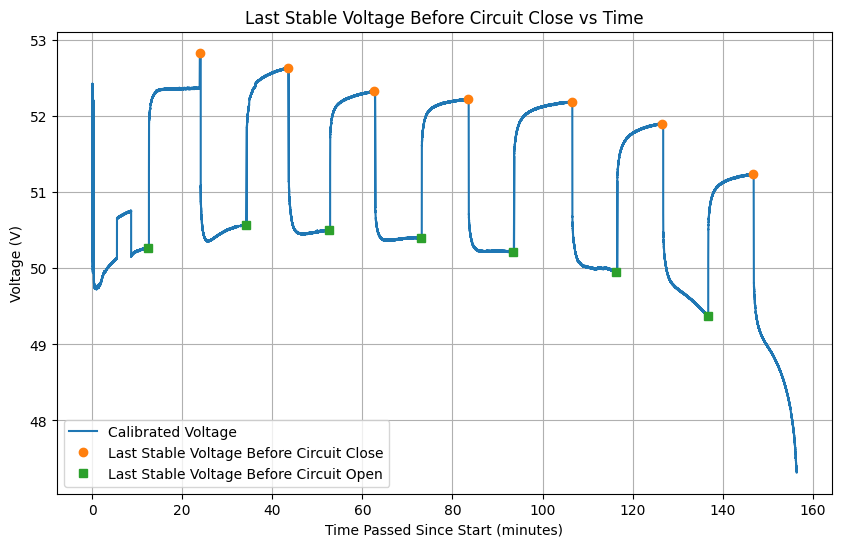

In [11]:
plt.figure(figsize=(10, 6))
plt.plot(combined_df['Translated Time (minutes)'], combined_df['Calibrated Voltage'], label='Calibrated Voltage')
plt.plot(last_stable_voltages_before_close['time'], last_stable_voltages_before_close['voltage'], 'o', label='Last Stable Voltage Before Circuit Close')
plt.plot(last_stable_voltages_before_open['time'], last_stable_voltages_before_open['voltage'], 's', label='Last Stable Voltage Before Circuit Open')
plt.xlabel('Time Passed Since Start (minutes)')
plt.ylabel('Voltage (V)')
plt.title('Last Stable Voltage Before Circuit Close vs Time')
plt.legend()
plt.grid()
plt.show()

In [12]:
isCloseFiltered = False
isOpenFiltered = False

In [13]:
create_csv_output_file(override=True, csv_data=combined_df)

In [14]:
outpus_json_points = {
    "before_close": {
        "index": last_stable_voltages_before_close['index'],
        "time": last_stable_voltages_before_close['time'],
        "voltage": last_stable_voltages_before_close['voltage']
    },
    "before_open": {
        "index": last_stable_voltages_before_open['index'],
        "time": last_stable_voltages_before_open['time'],
        "voltage": last_stable_voltages_before_open['voltage']
    }
}
print(f"Saved {len(last_stable_voltages_before_close['index'])} points for before close and {len(last_stable_voltages_before_open['time'])} points for before open to {points_of_interest_file_name}.")
json.dump(outpus_json_points, open(points_of_interest_file_name, 'w'), indent=4)

Saved 7 points for before close and 7 points for before open to C:\Users\Kor\Documents\GitHub\solar_proa_network_server\final_report\Calibration Code\LiFePO4 Patch Output\points_of_interest.json.
